# 03-RAG电商服装知识库问答项目

本篇对应课程第 3 份课件《03RAG项目》，把前两篇学习的 RAG、向量存储、Prompt 和会话记忆组合成一个可运行项目。项目以某东商品服装为例，使用本地服装属性资料构建知识库，用户通过网页提问，系统检索本地知识并调用大模型生成回答。

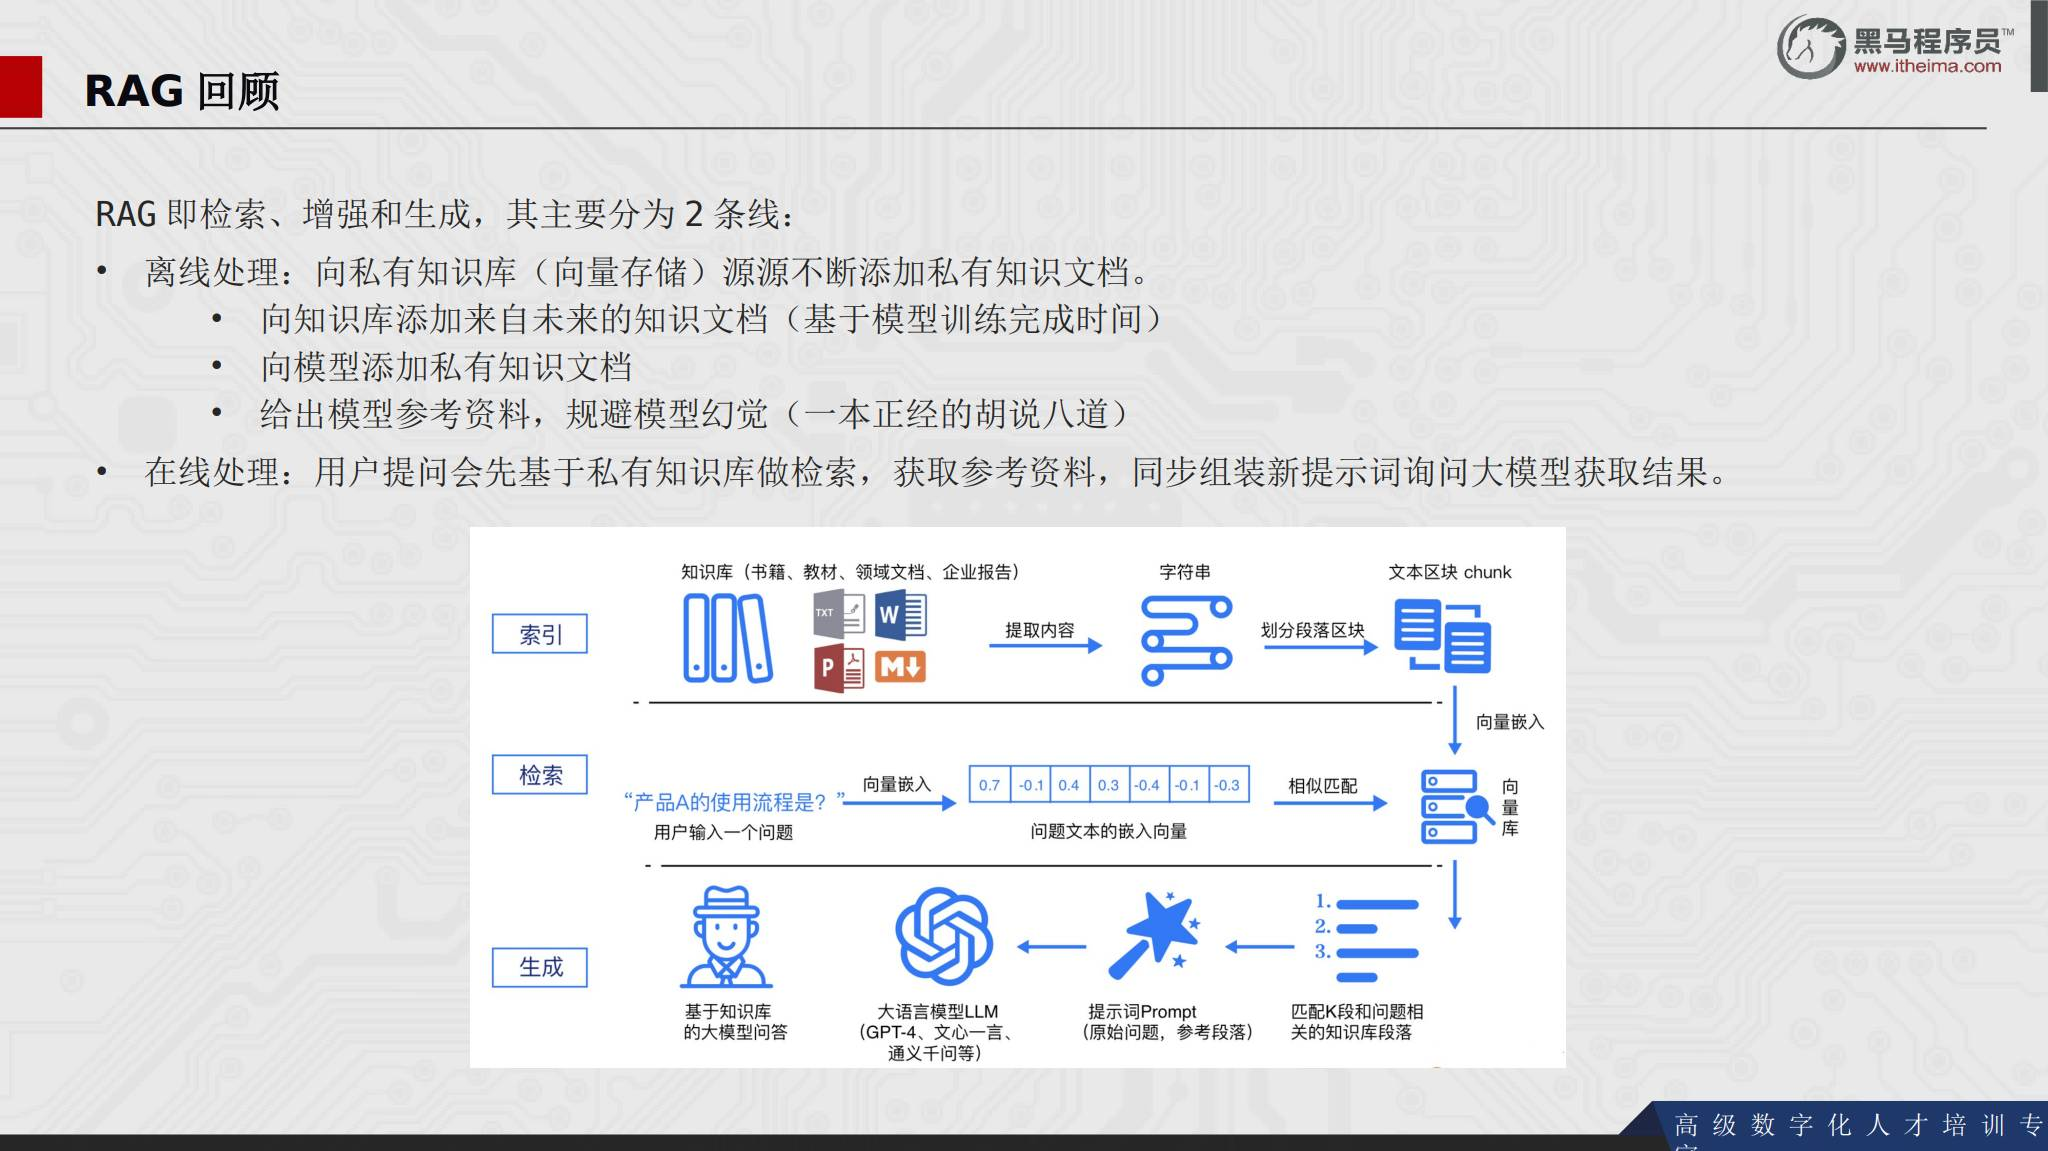


## 1. 项目要解决的问题

普通大模型不知道项目私有的商品资料，直接回答尺码、洗涤或颜色等问题时，可能出现知识缺失或幻觉。这个项目希望做到：

- 用户可以自由更新本地知识文件。
- 知识库由本地资料构建，不依赖模型训练数据记忆商品信息。
- 用户提问先检索相关服装属性，再把参考资料交给大模型。
- 回答基于本地知识生成，并且支持连续对话。

项目把“更新资料”和“用户问答”拆成离线、在线两条流程。

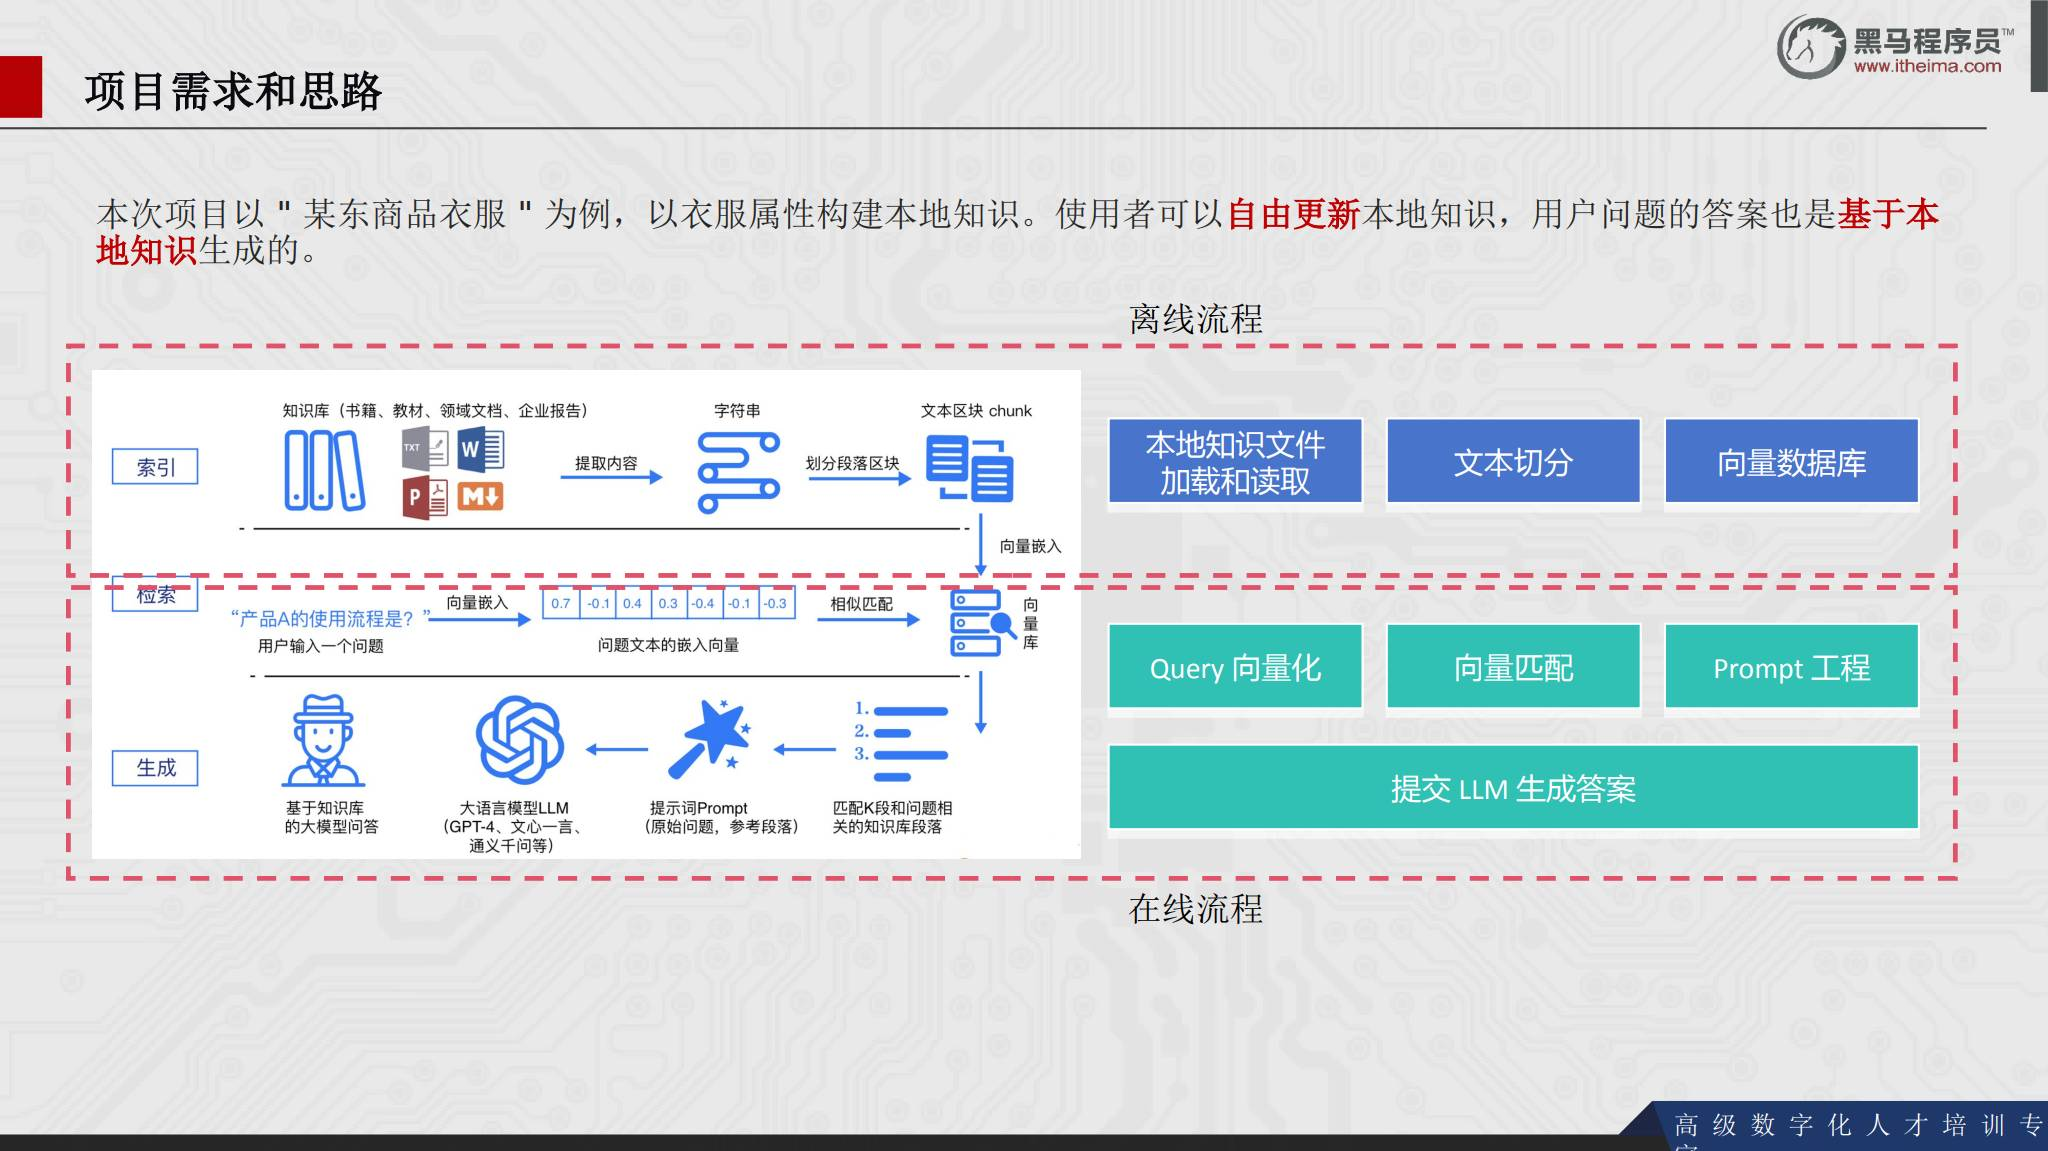


## 2. RAG 在项目中的两条流程

### 离线处理流程

```text
本地知识文件 → 加载和读取 → 文本切分 → 向量数据库
```

离线流程负责把服装属性资料处理成可检索的向量数据。知识文件更新后，需要重新执行对应的知识库更新流程。

### 在线问答流程

```text
用户 Query → Query 向量化 → 向量匹配 → Prompt 工程 → 提交 LLM → 生成答案
```

在线流程只围绕当前问题检索相关片段，再把问题和参考资料组合为新的 Prompt。

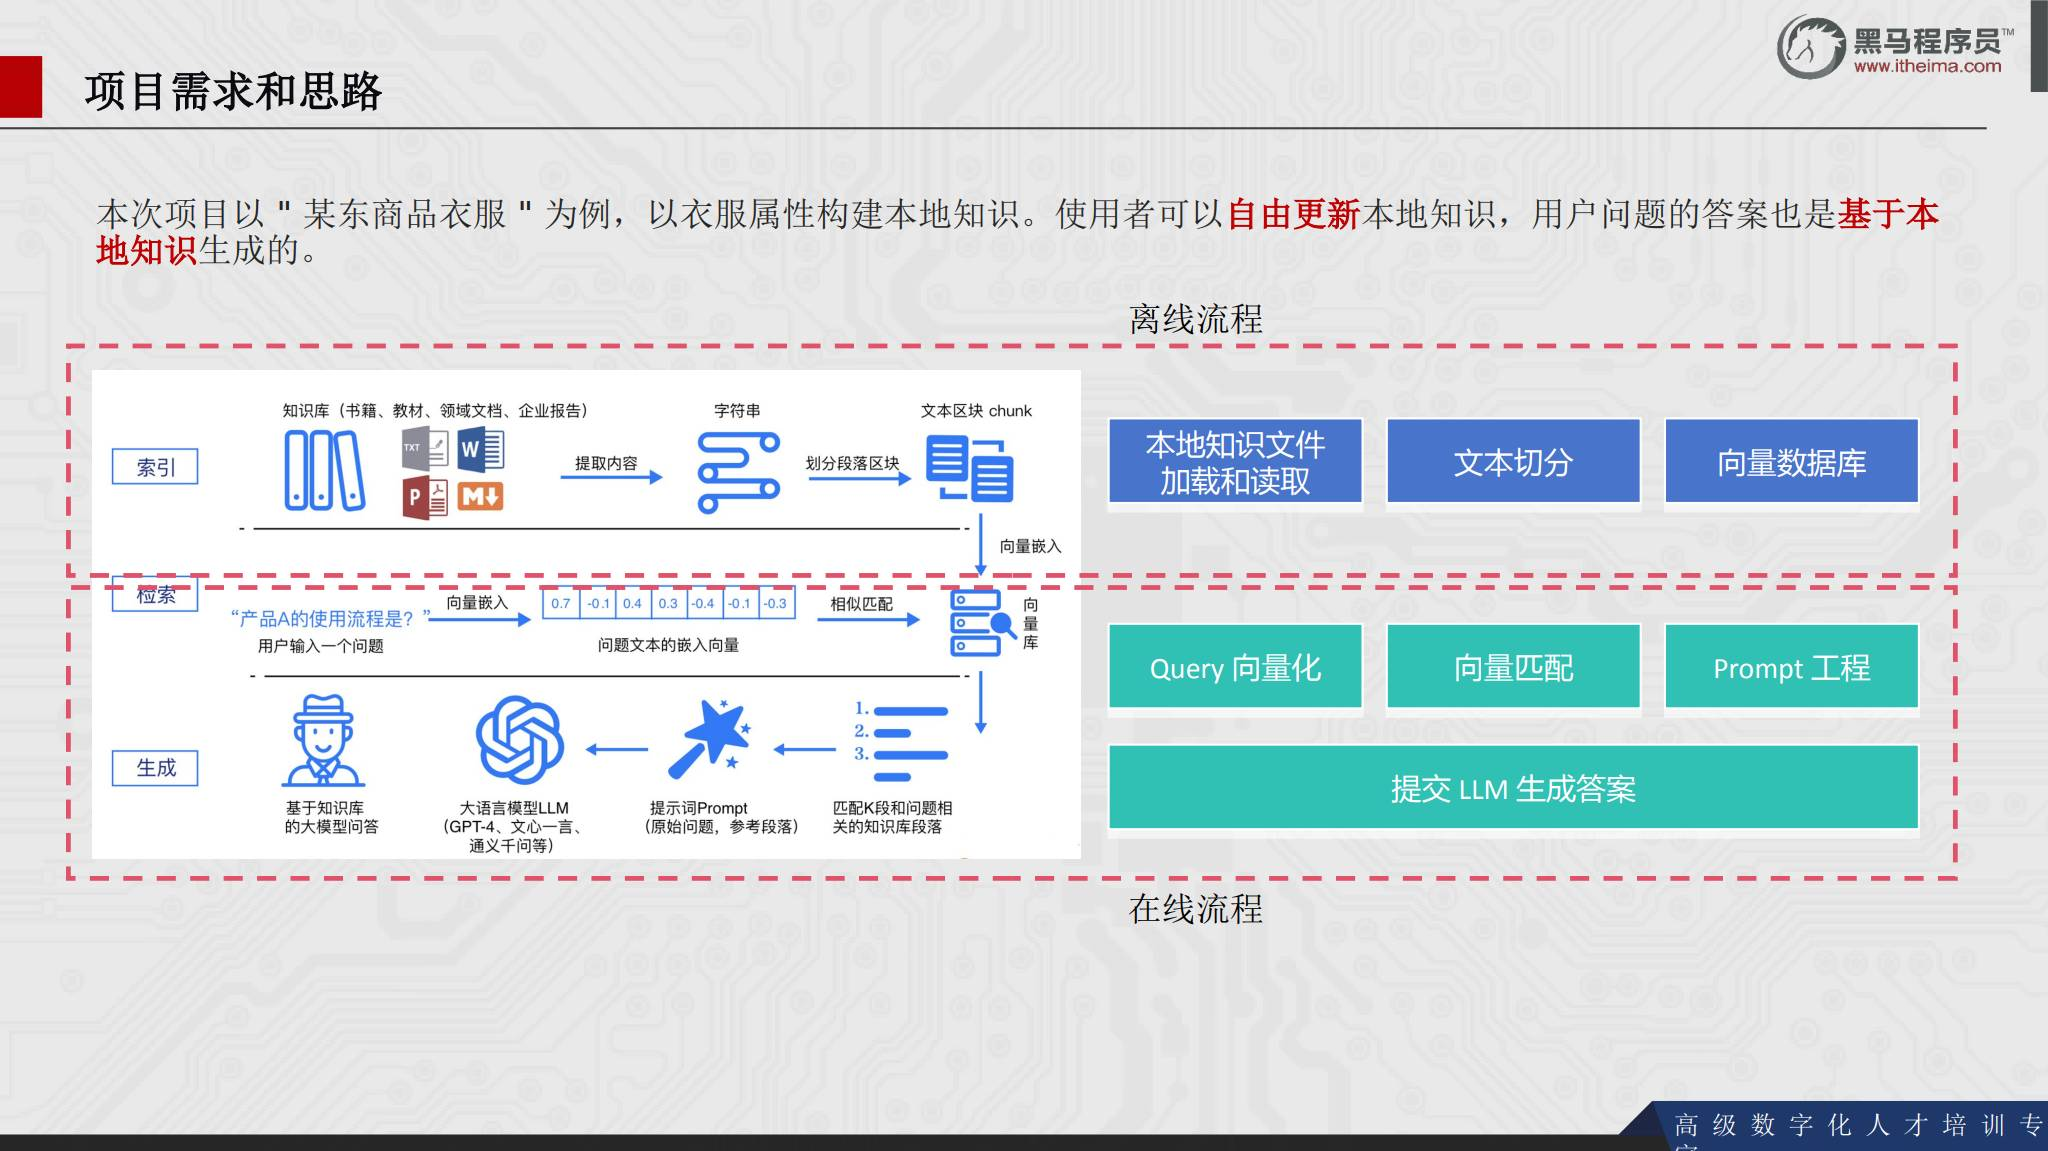


## 3. 项目架构中的代码文件

课件列出了项目主要文件：

| 文件 | 课程中的职责 |
| --- | --- |
| `app_file_upload.py` | Streamlit 知识库更新主程序，负责上传或更新资料 |
| `app_qa.py` | Streamlit 项目主程序，启动对话 Web 页面 |
| `config_data.py` | 配置文件，集中保存项目运行配置 |
| `file_history_store.py` | 长期会话记忆存储服务 |
| `knowledge_base.py` | 知识库更新服务 |
| `rag.py` | RAG 核心服务 |
| `vector_stores.py` | 向量存储服务 |

文件按职责拆分后，网页入口、知识库更新、向量存储、RAG 生成和会话历史可以分别维护。

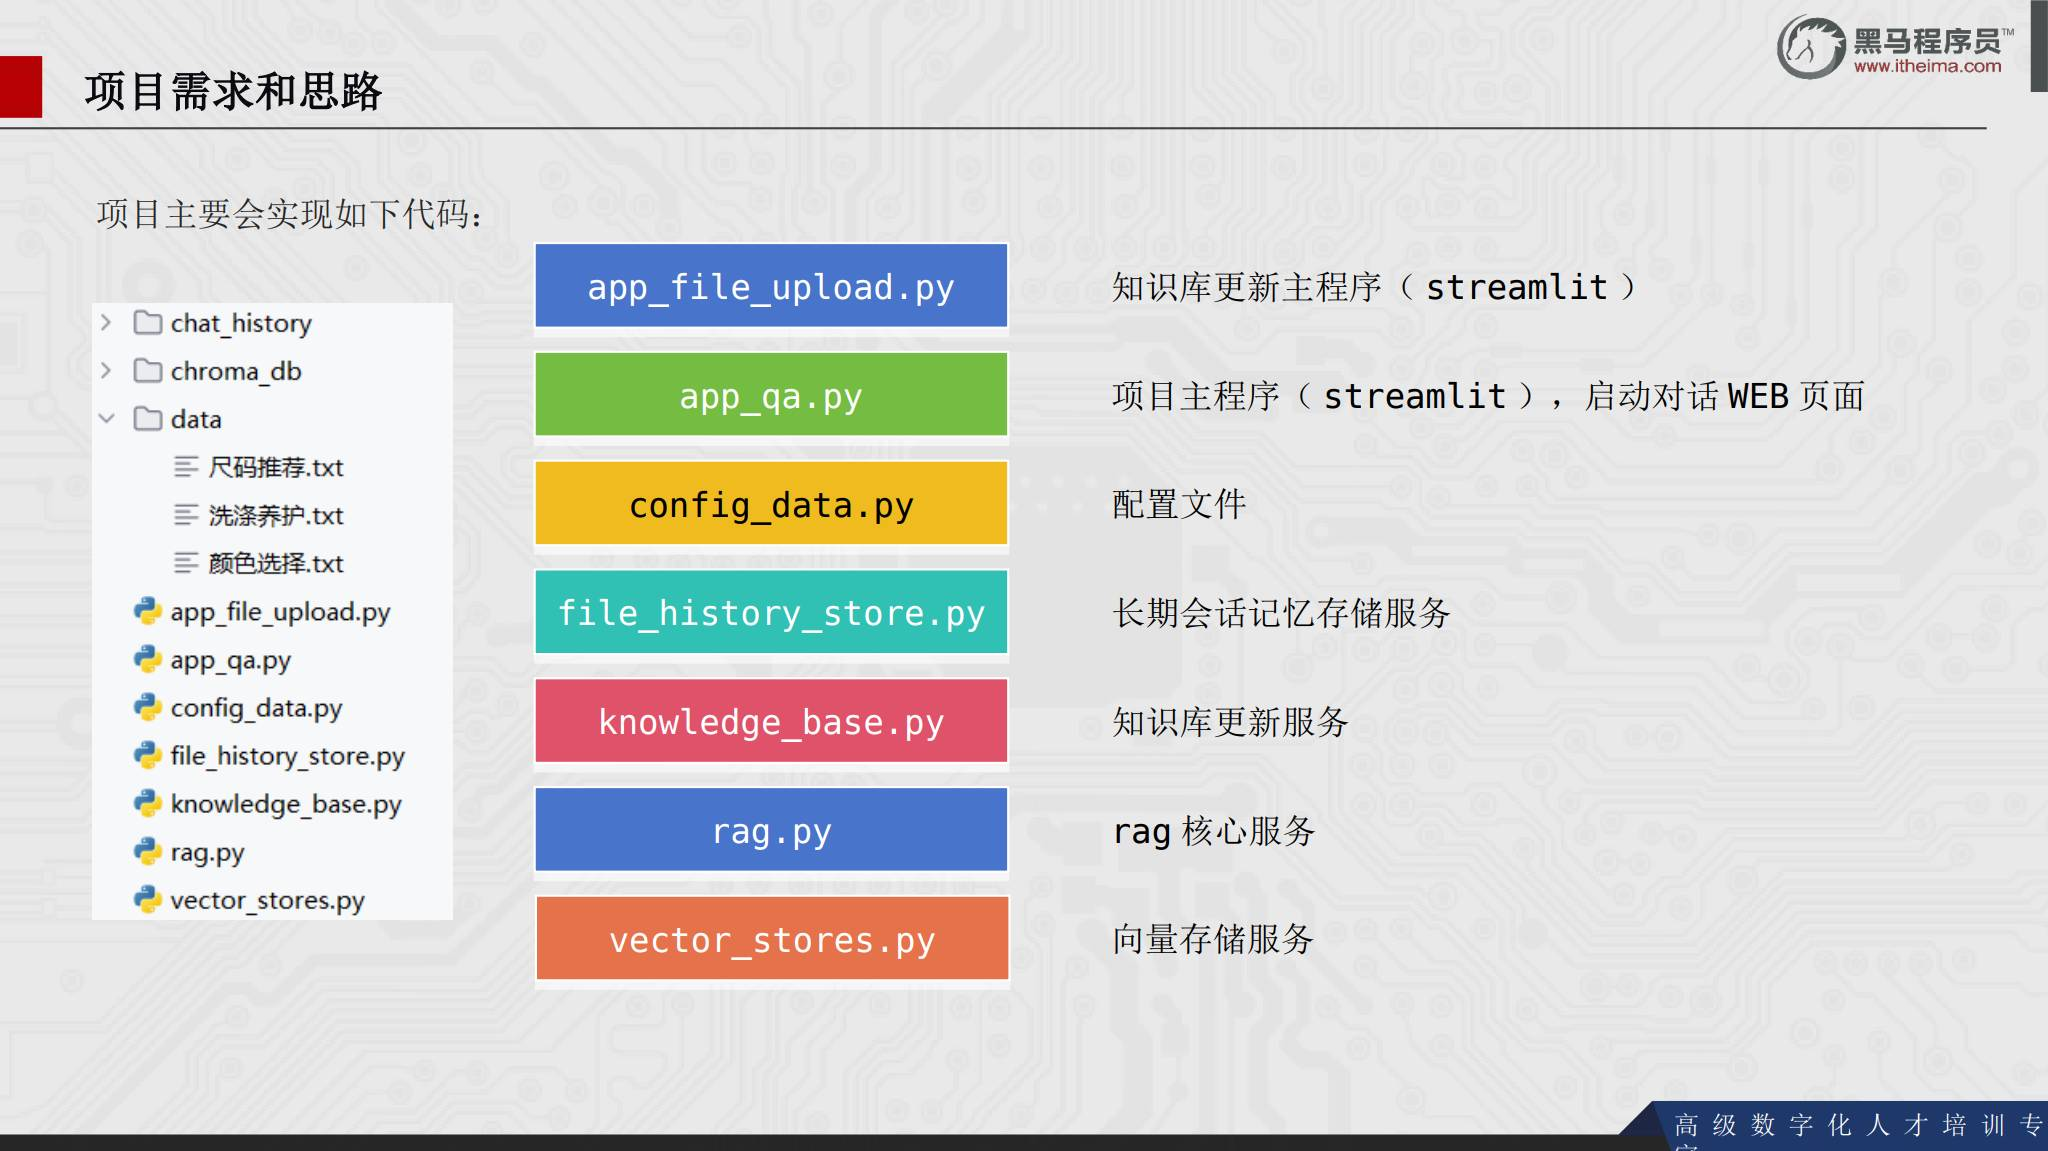


## 4. 代码模块之间的关系

可以按两个入口理解模块关系：

### 知识库更新入口

`app_file_upload.py` 提供 Streamlit 页面，调用 `knowledge_base.py` 读取和处理文件；处理过程中会用到 `config_data.py` 的路径和模型配置，并通过 `vector_stores.py` 写入向量数据库。

### 对话问答入口

`app_qa.py` 提供对话页面，调用 `rag.py` 完成检索、Prompt 组合和模型生成；向量检索由 `vector_stores.py` 提供，连续对话记录由 `file_history_store.py` 保存。

这是一种按职责划分的项目结构，课件没有给出完整函数签名和目录树，实际代码以课程项目文件为准。


## 5. 离线流程：更新知识库

离线流程的任务是把本地服装资料转换成向量数据库中的知识：

1. 用户在 `app_file_upload.py` 页面选择或上传本地知识文件。
2. `knowledge_base.py` 读取文件内容。
3. 将长文本切分成适合检索的片段。
4. 使用嵌入模型把片段转换成向量。
5. 通过 `vector_stores.py` 把向量和原文片段保存到向量数据库。
6. 后续问答可以直接检索这批知识。

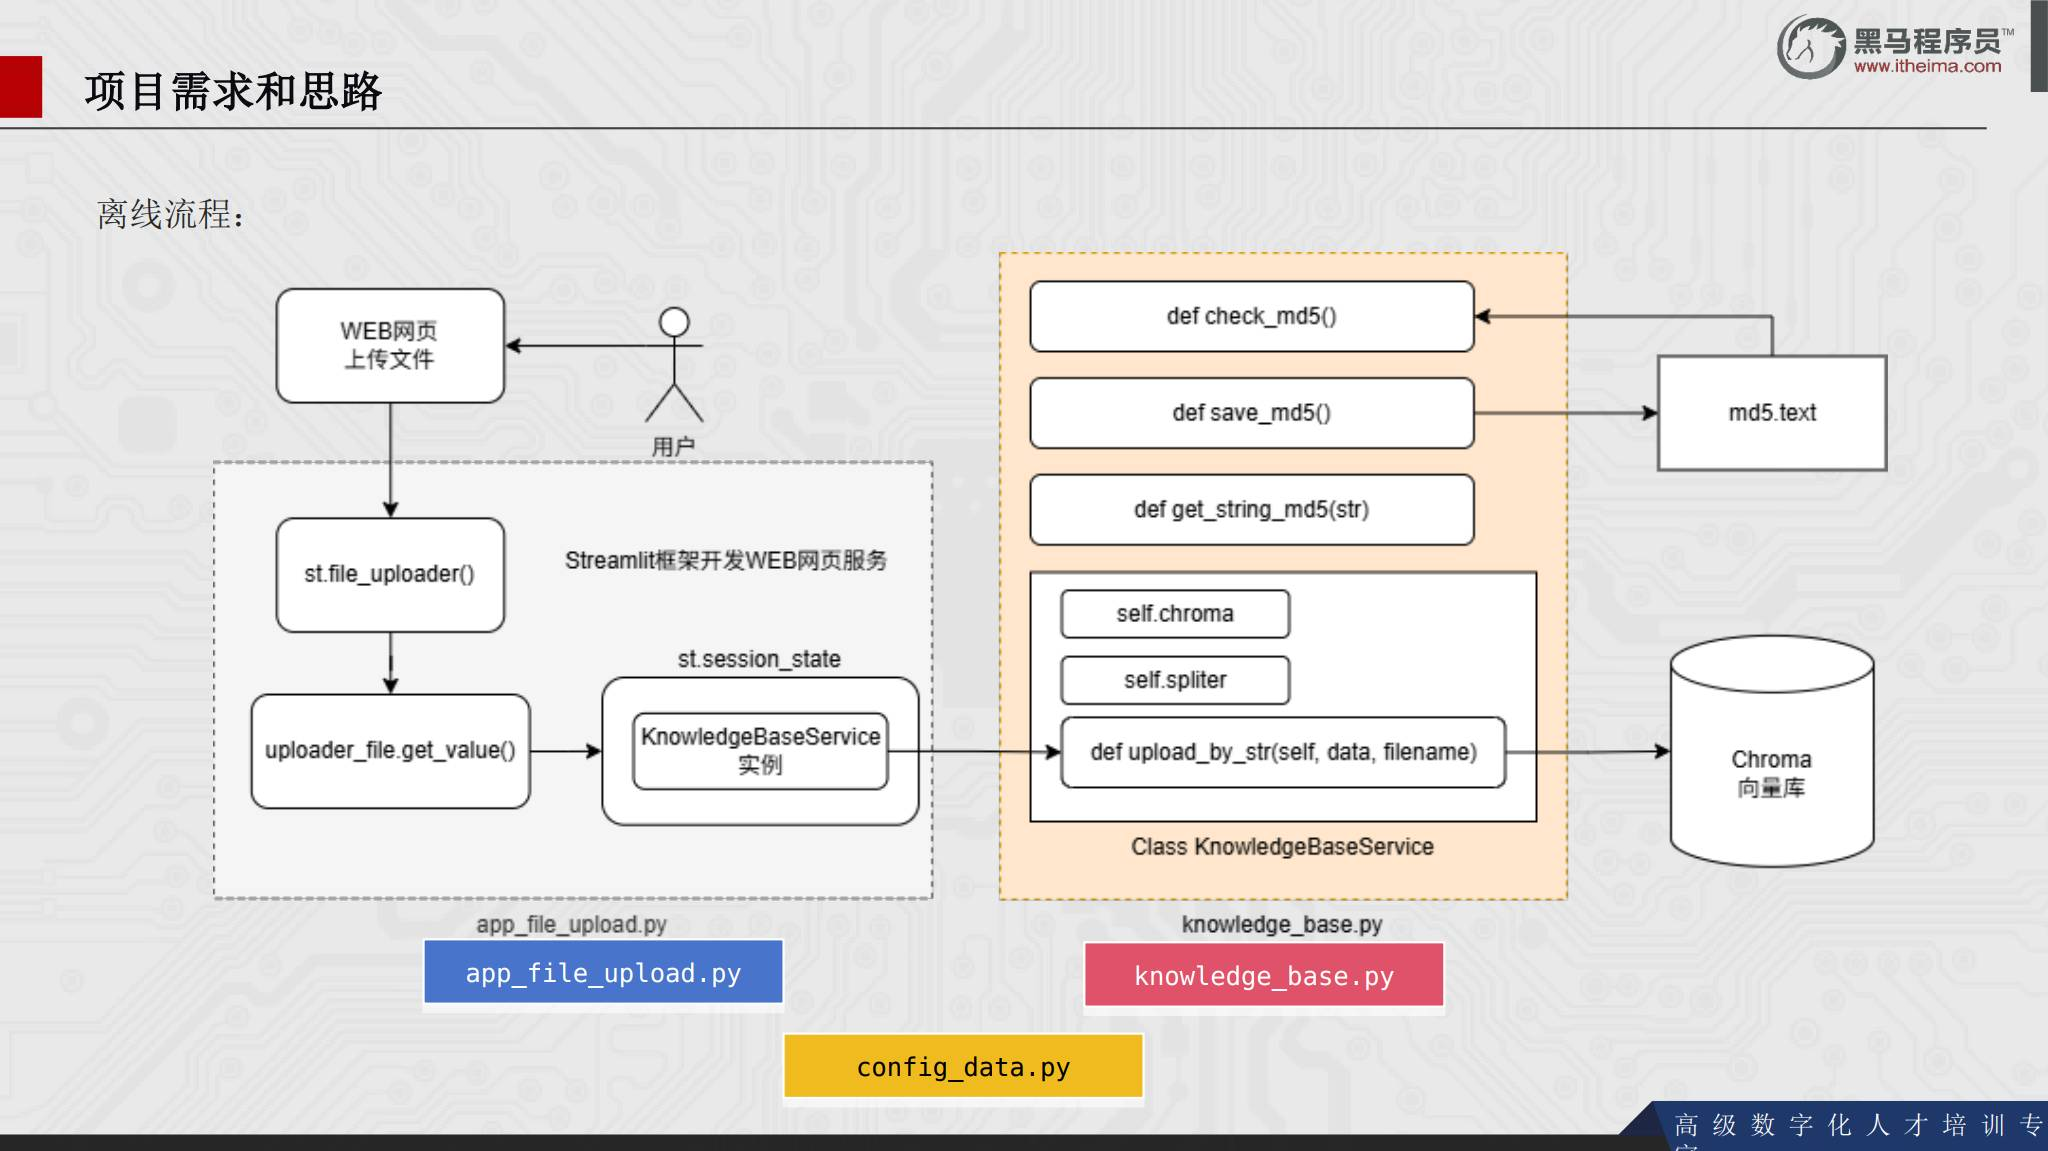


## 6. 知识文件更新时要注意什么

项目允许使用者自由更新本地知识，因此更新过程要保持一致：

- 文件内容应该围绕服装商品属性，避免混入与商品无关的材料。
- 文件读取、切分和向量化应使用与首次建库一致的配置。
- 更新后要确认向量数据库已经写入新片段。
- 如果旧知识仍然存在，要明确采用追加、覆盖还是重建策略。

课件强调的是“本地知识可更新”，没有展开具体的去重、版本和删除策略；这些策略应在项目代码中明确后再投入使用。


## 7. 在线流程：从问题到回答

用户在 `app_qa.py` 页面输入问题后，`rag.py` 按下面顺序处理：

1. 接收用户 Query。
2. 调用嵌入模型，把 Query 转成向量。
3. 在向量数据库中检索相似的服装知识片段。
4. 将问题和检索到的参考资料放入 Prompt。
5. 调用大模型生成答案。
6. 把答案展示在网页中，并把对话记录交给会话存储服务。

如果没有相关知识，项目应根据 Prompt 规则明确说明资料不足，避免把模型记忆当成本地商品事实。

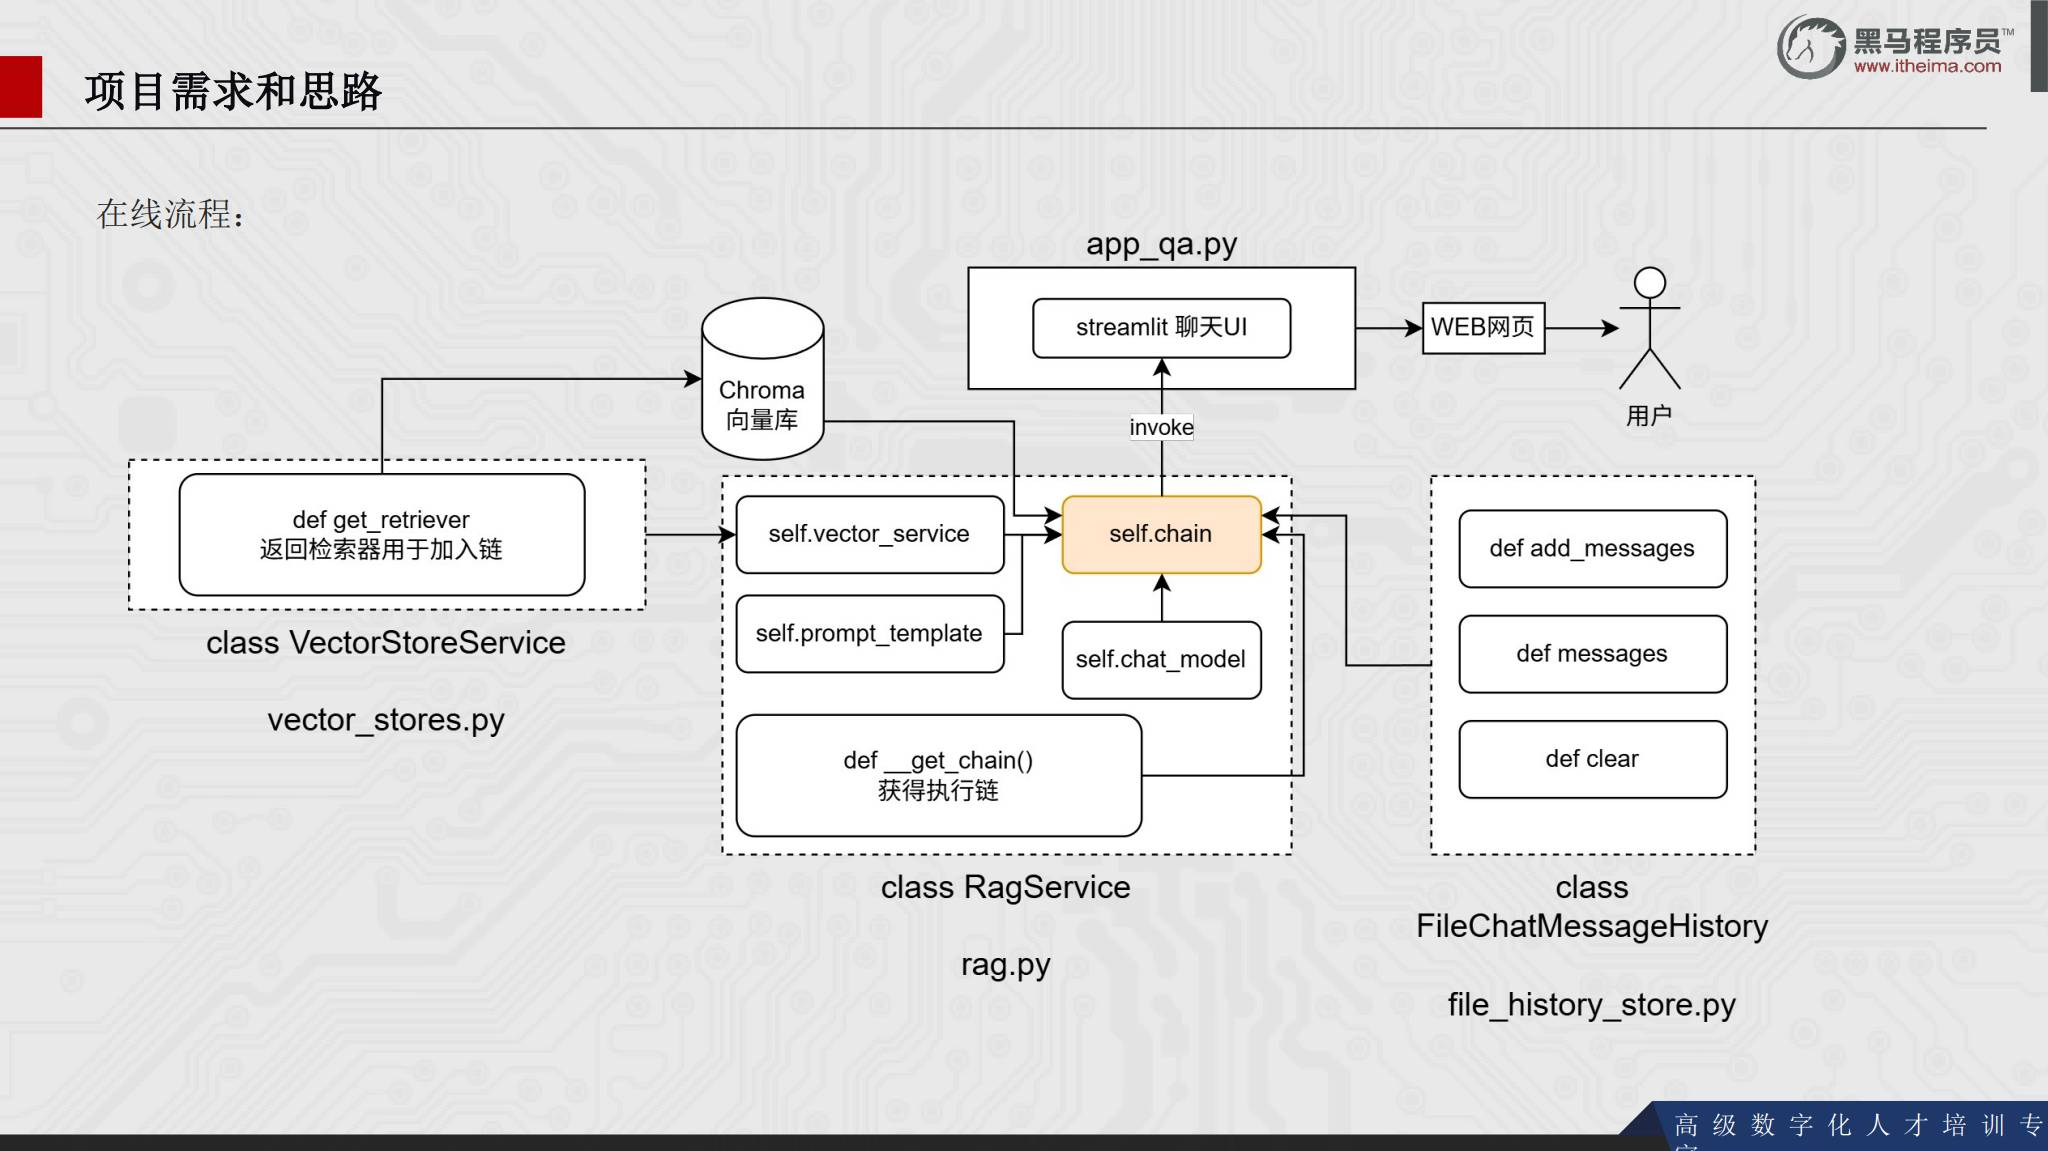


## 8. RAG 核心服务的职责

`rag.py` 是在线问答的核心服务，主要负责把各组件串起来：

| 输入或组件 | 处理 | 输出 |
| --- | --- | --- |
| 用户问题 | 问题向量化 | Query 向量 |
| Query 向量 | 相似度搜索 | 相关文档片段 |
| 问题 + 文档片段 | 组装 Prompt | 带上下文的模型输入 |
| Prompt | 调用 LLM | 商品问答结果 |

`rag.py` 不应该把向量库实现、网页展示和文件上传逻辑全部混在一起。向量操作交给 `vector_stores.py`，页面交给 Streamlit 入口文件，职责清楚后更容易替换组件。


## 9. 向量存储服务的职责

`vector_stores.py` 负责向量数据库相关操作，至少需要支持：

- 创建或连接向量存储。
- 添加文本片段和对应向量。
- 根据 Query 做相似度检索。
- 在知识更新时处理旧数据或重建数据。

它向上层提供统一接口，让 `knowledge_base.py` 只关心“写入知识”，让 `rag.py` 只关心“检索知识”。


## 10. 长期会话记忆

服装问答可能是连续对话，例如用户先问某件衣服的尺码，再追问清洗方法。`file_history_store.py` 用于长期保存会话记录，使程序重新启动后仍能区分不同会话并读取历史。

长期记忆需要至少明确：

1. 会话 ID 如何生成和传递。
2. 每个会话保存在哪个文件或目录。
3. 消息采用什么格式序列化。
4. 何时读取、追加和清理历史。

课件只列出长期存储服务文件，没有展示完整实现；具体持久化代码应结合前一篇 LangChain 记忆内容和项目源码阅读。


## 11. Streamlit 的两个页面

项目使用 Streamlit 提供两个 Web 页面：

| 页面 | 入口文件 | 用途 |
| --- | --- | --- |
| 知识库更新页面 | `app_file_upload.py` | 上传和更新本地服装知识 |
| 对话问答页面 | `app_qa.py` | 输入问题，查看基于知识库的回答 |

把两个入口分开后，资料维护和日常问答互不干扰。更新知识库时先在更新页面完成处理，再在问答页面验证新的知识是否能被检索到。


## 12. 项目验证顺序

可以按下面的顺序验证项目：

1. 启动知识库更新页面，上传本地知识文件。
2. 确认文件被读取、切分并写入向量数据库。
3. 启动对话问答页面。
4. 提问资料中明确出现的问题，检查回答是否引用正确知识。
5. 换一种说法询问同一内容，检查向量检索是否能找到相关片段。
6. 提问知识库没有覆盖的问题，观察系统是否按 Prompt 规则处理。
7. 连续追问，确认会话历史能够保留。
8. 更新知识文件后再次提问，确认新内容可检索。

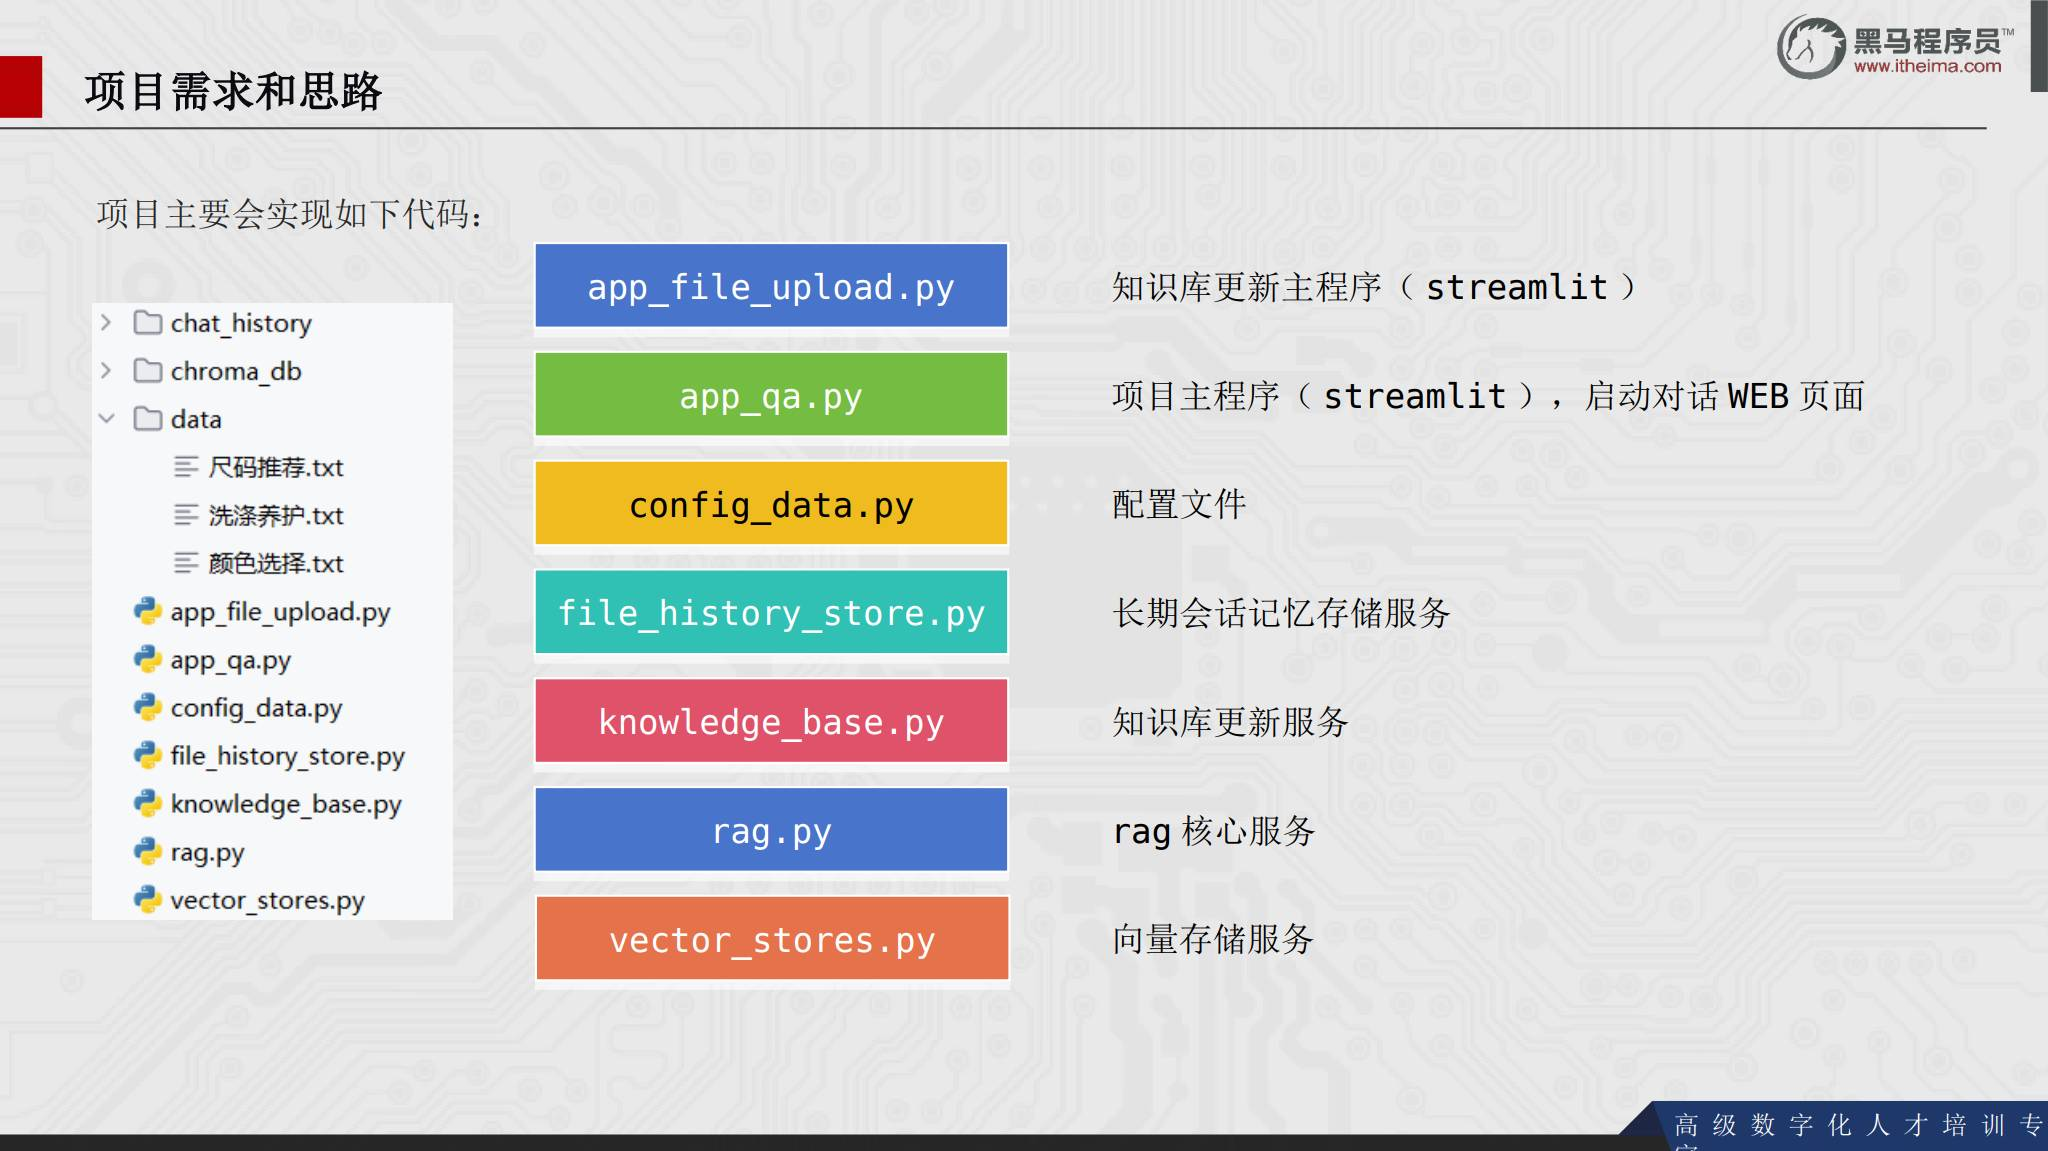


## 13. 项目中的关键边界

这个项目的答案来源是本地服装知识，不是模型的通用记忆。调试时要区分三个问题：

- **知识没有写入**：离线更新流程或向量存储有问题。
- **知识没有检索到**：嵌入模型、切片或相似度检索有问题。
- **检索到了但回答不对**：Prompt、模型或上下文拼接有问题。

把问题定位到对应阶段，比只看最终回答更容易修复系统。


## 14. 三篇课程内容如何接起来

三份课件形成一条完整学习路径：

1. 第 1 篇学习模型接入、OpenAI SDK、Ollama 和提示词工程。
2. 第 2 篇学习 LangChain、文档加载、文本切分、向量存储和检索链。
3. 第 3 篇把这些能力拆成代码模块，组成可更新知识库和可交互问答页面。

项目的离线流程使用第 2 篇的文档处理和向量存储，在线流程使用第 1 篇的模型与 Prompt，再通过第 2 篇的 Runnable 链和记忆能力把它们连接起来。


## 15. 本章小结

本项目以商品服装知识为例，完成了一个本地 RAG 问答应用的架构设计：

- 用 `app_file_upload.py` 管理知识库更新。
- 用 `knowledge_base.py` 读取、切分和向量化资料。
- 用 `vector_stores.py` 保存和检索向量。
- 用 `app_qa.py` 提供对话页面。
- 用 `rag.py` 组织 Query、检索、Prompt 和 LLM 生成。
- 用 `file_history_store.py` 保存长期会话。
- 用 Streamlit 把离线维护和在线问答交付成 Web 页面。


## 16. 资料边界

本篇依据第 3 份课件的 10 页内容整理了项目需求、离线与在线流程、代码文件职责和验证顺序。课件没有给出完整函数实现、目录结构、数据库配置或 Streamlit 启动命令，因此本篇保留架构和模块边界，不虚构课件之外的工程代码。
